# Archive: parameter tests
Early experiments with number of rays, ring count and plotting. Kept for documentation; the final settings are 8 rays, 1 m steps and 6 rings of 6 m.

In [ ]:
# --- Project paths ------------------------------------------------------------
# Modules are in src/, data in data/, results in results/, figures in figures/.
# Works no matter from which folder the notebook is started.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(ROOT / "src"))

from paths import data, DATA_RAW, DATA_PROCESSED, RESULTS, FIGURES
import helpers
helpers.FIG_DIR = FIGURES / "parameter_tests"     # save_fig() writes here
helpers.FIG_DIR.mkdir(parents=True, exist_ok=True)

In [61]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from cycler import cycler
from kiln_ring_analysis import kiln_ring_analysis, DEFAULTS as ANALYSIS_DEFAULTS
from plot_kiln_rings import plot_kiln_rings, DEFAULTS as PLOT_DEFAULTS
from helpers import save_fig


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


For a constant look, we define a colour scheme to be used for all graphs:

In [62]:
COLSCHEME = {
       "ember":  ["#FDBE85", "#F68C3A", "#D9541A"],
       "forest": ["#A8DDB5", "#4DAF6E", "#23794A"],
       "smoke":  ["#A6CEE3", "#4A90C8", "#2563A0"]
       }

plt.rcParams["axes.prop_cycle"] = cycler(color=[COLSCHEME["smoke"][2], COLSCHEME["ember"][2],
                                                COLSCHEME["forest"][2], COLSCHEME["smoke"][1],
                                                COLSCHEME["ember"][1], COLSCHEME["forest"][1]])

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "pdf.fonttype": 42,
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

***
## Display raw data
In this chapter we will start with 16 rays, 1m sample intervals and 6m ring intervals (up to 24m). The samples are not weighted.  

The analysis results are saved in: `new testfolder/results/merged_dem_rays16_step1_ring6x4`

### Run analysis

## 4 rings of 6 m with 16 rays

In [63]:
params = {
    "gpkg": data("kohlmeiler_2056.gpkg"),
    "tif": data("merged_dem.tif"),
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24)],
    "n_rays": 16,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

rings = [(0, 6), (6, 12), (12, 18), (18, 24)]

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          16 (every 22.5°), sample every 1 m up to 24 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 96 samples
       6-12    m: 96 samples
      12-18    m: 96 samples
      18-24    m: 96 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m
count   79.00   79.00    79.00    79.00
median   6.20    5.93     6.14     6.06
mean     6.73    6.45     6.39     6.53
std      3.88    3.55     3.50     3.37
min      0.00    0.00     0.00     0.19
25%      4.66    4.60     4.23     4.79
50%      6.20    5.93     6.14     6.06
75%      8.54    8.56     7.47     7.86
max     19.02   16.17    17.76    17.15

Rings left empty (too little valid data):
   mean_0_6: kilns [12]
   mean_6_12: kiln

### Plot function
Here, we define a function for plotting the raw outpur of the analysis. It plots each ray of each kiln. The function includes the possibility to smooth the output of each ray with a moving window. This is done to reduce the impact that noise has on the visualisation, hiding the trends we are looking for.

In [64]:
def plot_raw_rays(samples: pd.DataFrame, rings: list, window_size=1, l_alpha=0.1, st_dev=False, color=COLSCHEME, ctrl_samples=None, y_label=None):
    samples = samples.sort_values(["kiln_id", "ray", "distance"])
    samples["smooth"] = (samples.groupby(["kiln_id", "ray"])["value"].transform(lambda v: v.rolling(window_size, center=True, min_periods=1).mean()))

    def smooth(s):
        s = s.sort_values(["kiln_id", "ray", "distance"]).copy()
        s["smooth"] = s.groupby(["kiln_id", "ray"])["value"].transform(
            lambda v: v.rolling(window_size, center=True, min_periods=1).mean())
        return s

    samples = smooth(samples)
    fig, ax = plt.subplots(figsize=(6.3,3))

    # all lines
    for _, line in samples.groupby(["kiln_id", "ray"]):
        ax.plot(line["distance"], line["smooth"], color=color["forest"][1], alpha=l_alpha, lw=0.8)

    # mean ± 1 SD per distance, for the kilns and (optionally) the controls
    groups = [("Charcoal mounds", samples, color["ember"])]
    if ctrl_samples is not None:
        groups.append(("Controls", smooth(ctrl_samples), color["smoke"]))
    for label, s, c in groups:
        per_dist = s.groupby("distance")["smooth"]
        m, sd = per_dist.mean(), per_dist.std()
        ax.plot(m.index, m + sd, color=c[2], lw=0.8, ls="--", label=f"{label}: mean ± 1 SD")
        ax.plot(m.index, m - sd, color=c[2], lw=0.8, ls="--")
        ax.plot(m.index, m, color=c[2], lw=1.5, label=f"{label}: mean")

    # ring interval boundaries
    for _, outer in rings[:-1]:
        ax.axvline(outer, color="black", lw=0.6, ls=":", alpha=0.6)

    ax.set_xlim(0,rings[-1][-1])
    ax.set_ylim(0, max(samples["smooth"])+2)
    ax.set_xlabel("Distance from mound (m)")
    if y_label:
        ax.set_ylabel(y_label)
    elif window_size == 1:
        ax.set_ylabel(f"Canopy height (m)")
    else:
        ax.set_ylabel(f"Smoothed canopy height (m) (window={window_size})")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig

### Plotting
We can now play with the plotting settings.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


[PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/rays16_step1_ring6x4_raw.png.png'),
 PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/rays16_step1_ring6x4_raw.png.pdf')]

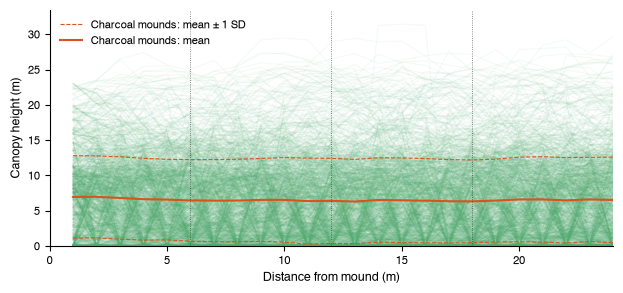

In [65]:
kiln_samples = pd.read_csv(str(RESULTS / "merged_dem_rays16_step1_ring6x4/merged_dem_samples.csv"))

fig = plot_raw_rays(kiln_samples, rings, window_size=1, l_alpha=0.06)
save_fig("rays16_step1_ring6x4_raw", fig=fig)

This plot is very messy. Mainly due to the zig zag pattern at the bottom which is a result of pixels with value 0 representing the floor. There are a lot of rays that have floor pixels in the so this zig zag pattern cannot be avoided when plotting the raw pixel data.  

What can be seen is that on the very left, rays share pixel values due to the number of rays and the liimited number of pixels for small radii. This results in these few darker lines, indicating shared values. Once the radius is large enough that each ray has its own pixels, such artefacts disappear.  

**Floating average**  

What we can do is calculate a floating average for each pixel with a given window size. Let's try it with window size = 3 (i.e. it looks one pixel to the left and one to the right)

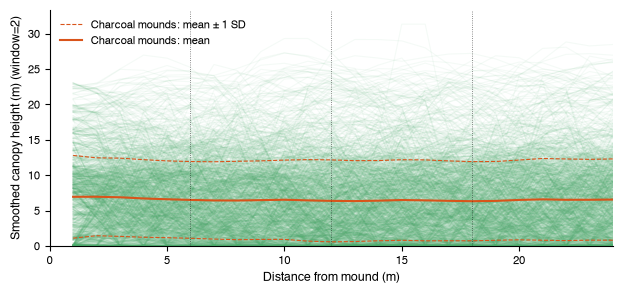

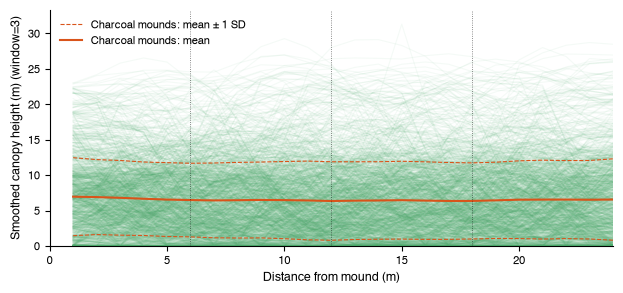

In [66]:
res_2 = plot_raw_rays(samples=kiln_samples, rings=rings, window_size=2, l_alpha=0.06)
res_3 = plot_raw_rays(samples=kiln_samples, rings=rings, window_size=3, l_alpha=0.06)

I don't know, whether these last 3 graphs are suitable for the report since the idea of this kind of graph is to truly show the data and how it looks like. The zig zag is not an artefact, it's part of the data. And the median and mean lines can still be interpreted well.

## 6 rings of 6 m with 8 rays

In [67]:
rings = [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)]
params_kiln = {
    "gpkg": data("kohlmeiler_2056.gpkg"),
    "tif": data("merged_dem.tif"),
    "rings": rings,
    "n_rays": 8,
    "step": 1,
    "weighted": False
}
params_kiln_red = {
    "gpkg": data("kohlmeiler_2056_reduced.gpkg"),
    "tif": data("merged_dem.tif"),
    "rings": rings,
    "n_rays": 8,
    "step": 1,
    "weighted": False
}
params_control = {
    "gpkg": data("controls_2056_36_150.gpkg"),
    "tif": data("merged_dem.tif"),
    "rings": rings,
    "n_rays": 8,
    "step": 1,
    "weighted": False
}

out_kiln = kiln_ring_analysis(params_kiln)
out_kiln_red = kiln_ring_analysis(params_kiln_red)
out_control = kiln_ring_analysis(params_control)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          8 (every 45°), sample every 1 m up to 36 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 48 samples
       6-12    m: 48 samples
      12-18    m: 48 samples
      18-24    m: 48 samples
      24-30    m: 48 samples
      30-36    m: 48 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m
count   79.00   79.00    79.00    79.00    79.00    77.00
median   6.11    5.52     5.73     6.14     5.93     6.03
mean     6.74    6.40     6.40     6.50     6.46     6.77
std      3.87    3.62     3.69     3.58     3.20     3.47
min      0.00    0.00     0.00     0.00     0.64     0.62
25%      4.70    4.61     4.13     4.46     4.67     4.68
50%      6.11    5.52   

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


[PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/rays8_step1_ring6x6_red_controls.png.png'),
 PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/rays8_step1_ring6x6_red_controls.png.pdf')]

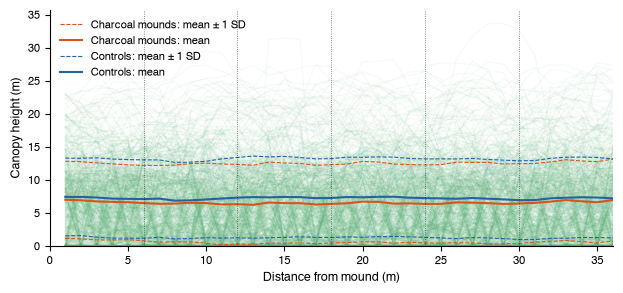

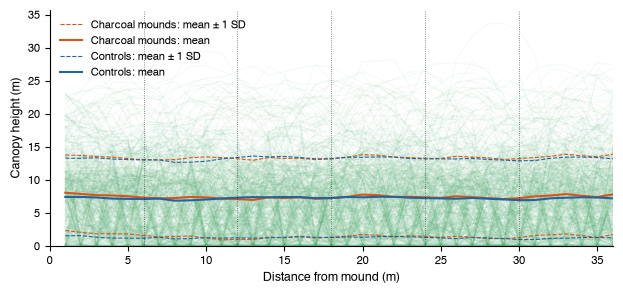

In [68]:
kiln_samples = pd.read_csv(str(RESULTS / "merged_dem_rays8_step1_ring6x6/merged_dem_samples.csv"))
kiln_red_samples = pd.read_csv(str(RESULTS / "merged_dem_rays8_step1_ring6x6_reduced/merged_dem_reduced_samples.csv"))
ctrl_samples = pd.read_csv(str(RESULTS / "merged_dem_rays8_step1_ring6x6_controls/merged_dem_controls_samples.csv"))

fig = plot_raw_rays(kiln_samples, rings, window_size=1, l_alpha=0.06, ctrl_samples=ctrl_samples)
save_fig("rays8_step1_ring6x6_raw_controls", fig=fig)

fig = plot_raw_rays(kiln_red_samples, rings, window_size=1, l_alpha=0.06, ctrl_samples=ctrl_samples)
save_fig("rays8_step1_ring6x6_red_controls", fig=fig)

## 8 rings of 6m with 8 rays

In [69]:
rings = [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36), (36, 42), (42, 48)]
params_kiln_red = {
    "gpkg": data("kohlmeiler_2056_reduced.gpkg"),
    "tif": data("merged_dem.tif"),
    "rings": rings,
    "n_rays": 8,
    "step": 1,
    "weighted": False
}
params_control = {
    "gpkg": data("controls_2056_36_150.gpkg"),
    "tif": data("merged_dem.tif"),
    "rings": rings,
    "n_rays": 8,
    "step": 1,
    "weighted": False
}

out_kiln_red = kiln_ring_analysis(params_kiln_red)
out_control = kiln_ring_analysis(params_control)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         60 from kohlmeiler_2056_reduced.gpkg
Rays:          8 (every 45°), sample every 1 m up to 48 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 48 samples
       6-12    m: 48 samples
      12-18    m: 48 samples
      18-24    m: 48 samples
      24-30    m: 48 samples
      30-36    m: 48 samples
      36-42    m: 48 samples
      42-48    m: 48 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m  36-42 m  42-48 m
count   60.00   60.00    60.00    60.00    60.00    60.00    60.00    60.00
median   6.74    5.97     6.21     6.58     6.19     6.44     6.81     6.47
mean     7.69    7.25     7.22     7.52     7.29     7.63     7.65     7.02
std      3.49    3.10     3.33     3.21     3.05     3.32   

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


[PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/rays8_step1_ring6x8_red_controls.png.png'),
 PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/rays8_step1_ring6x8_red_controls.png.pdf')]

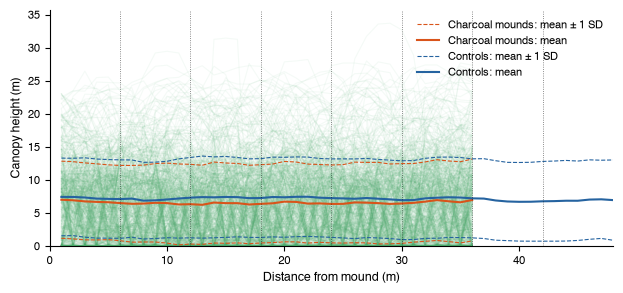

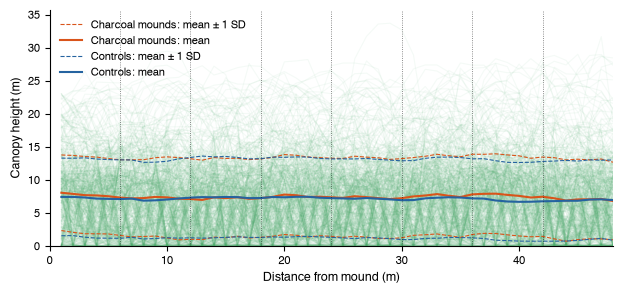

In [70]:
kiln_red_samples = pd.read_csv(str(RESULTS / "merged_dem_rays8_step1_ring6x8_reduced/merged_dem_reduced_samples.csv"))
ctrl_samples = pd.read_csv(str(RESULTS / "merged_dem_rays8_step1_ring6x8_controls/merged_dem_controls_samples.csv"))

fig = plot_raw_rays(kiln_samples, rings, window_size=1, l_alpha=0.06, ctrl_samples=ctrl_samples)
save_fig("rays8_step1_ring6x8_raw_controls", fig=fig)

fig = plot_raw_rays(kiln_red_samples, rings, window_size=1, l_alpha=0.06, ctrl_samples=ctrl_samples)
save_fig("rays8_step1_ring6x8_red_controls", fig=fig)